# Preventable Disease Risk Analysis — Milestone Three
**Kevin Bega — Module C: Data Science Capstone**

This notebook is the reproducible analysis companion to the Milestone Three technical report. It uses the same three UCI datasets as the earlier milestones: heart failure clinical records, obesity levels based on eating habits and physical condition, and cervical cancer risk factors.

The notebook documents data quality, preprocessing, exploratory analysis, supervised modeling, clustering, model comparison, and figure generation. All train/test preprocessing is fit only on training data through scikit-learn pipelines where applicable.

In [1]:
import os, json, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, silhouette_score, adjusted_rand_score,
    roc_curve
)

RANDOM_STATE = 42
BASE = '/mnt/data/m3work/data'
FIG = '/mnt/data/m3work/figures'
os.makedirs(FIG, exist_ok=True)

obesity = pd.read_csv(os.path.join(BASE, 'ObesityDataSet_raw_and_data_sinthetic.csv'))
heart = pd.read_csv(os.path.join(BASE, 'heart_failure_clinical_records_dataset.csv'))
cervical_raw = pd.read_csv(os.path.join(BASE, 'risk_factors_cervical_cancer.csv'))

print('Obesity:', obesity.shape)
print('Heart failure:', heart.shape)
print('Cervical cancer:', cervical_raw.shape)

Obesity: (2111, 17)
Heart failure: (299, 13)
Cervical cancer: (858, 36)


## 1. Data preparation

Targets are `NObeyesdad` (obesity), `DEATH_EVENT` (heart failure), and `Biopsy` (cervical cancer). For cervical cancer, the diagnostic outcome columns `Hinselmann`, `Schiller`, and `Citology` are excluded with the target to reduce outcome leakage. Question-mark missing values are converted to `NaN`; all remaining predictors are numeric-converted; and predictors with more than 40% missingness are removed.

In [2]:
# Cervical cleaning
cervical = cervical_raw.replace('?', np.nan).copy()
for c in cervical.columns:
    cervical[c] = pd.to_numeric(cervical[c], errors='coerce')

cervical_target = 'Biopsy'
leakage_cols = ['Hinselmann', 'Schiller', 'Citology', 'Biopsy']
X_cerv_full = cervical.drop(columns=leakage_cols)
missing_rate = X_cerv_full.isna().mean()
removed_high_missing = missing_rate[missing_rate > 0.40].index.tolist()
X_cerv = X_cerv_full.drop(columns=removed_high_missing)
y_cerv = cervical[cervical_target].astype(int)

print('Removed cervical predictors (>40% missing):', removed_high_missing)
print('Cervical predictors retained:', X_cerv.shape[1])
print('Biopsy positives:', int(y_cerv.sum()), 'of', len(y_cerv), f'({y_cerv.mean():.1%})')

Removed cervical predictors (>40% missing): ['STDs: Time since first diagnosis', 'STDs: Time since last diagnosis']
Cervical predictors retained: 30
Biopsy positives: 55 of 858 (6.4%)


In [3]:
# Dataset summary table
summary = pd.DataFrame({
    'Dataset': ['Obesity', 'Heart failure', 'Cervical cancer'],
    'Rows': [len(obesity), len(heart), len(cervical)],
    'Raw columns': [obesity.shape[1], heart.shape[1], cervical_raw.shape[1]],
    'Target': ['NObeyesdad', 'DEATH_EVENT', 'Biopsy'],
    'Target type': ['7-class', 'Binary', 'Binary'],
    'Positive/event count': ['n/a', int(heart.DEATH_EVENT.sum()), int(y_cerv.sum())],
    'Missing-data note': ['None in file', 'None in file', "'?' converted to missing; >40% columns removed"]
})
summary

,Dataset,Rows,Raw columns,Target,Target type,Positive/event count,Missing-data note
0,Obesity,2111,17,NObeyesdad,7-class,n/a,None in file
1,Heart failure,299,13,DEATH_EVENT,Binary,96,None in file
2,Cervical cancer,858,36,Biopsy,Binary,55,'?' converted to missing; >40% columns removed


## 2. Exploratory data analysis

The figures below emphasize class balance, missingness, and relationships that directly influence modeling decisions.

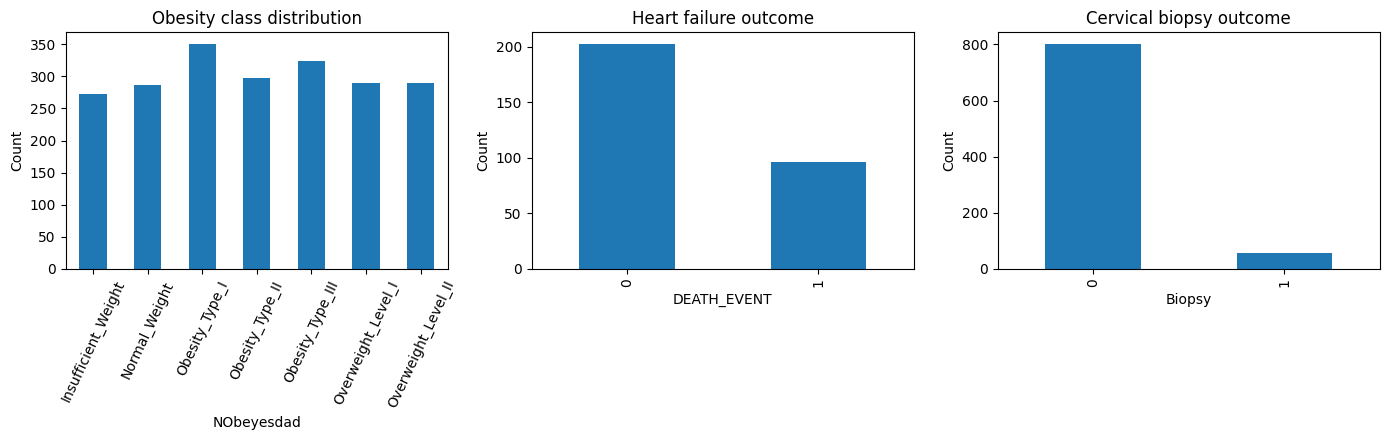

In [4]:
# Figure 1: target distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
obesity['NObeyesdad'].value_counts().sort_index().plot(kind='bar', ax=axes[0])
axes[0].set_title('Obesity class distribution')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=65)
heart['DEATH_EVENT'].value_counts().sort_index().plot(kind='bar', ax=axes[1])
axes[1].set_title('Heart failure outcome')
axes[1].set_xlabel('DEATH_EVENT')
axes[1].set_ylabel('Count')
cervical['Biopsy'].value_counts().sort_index().plot(kind='bar', ax=axes[2])
axes[2].set_title('Cervical biopsy outcome')
axes[2].set_xlabel('Biopsy')
axes[2].set_ylabel('Count')
plt.tight_layout()
plt.savefig(os.path.join(FIG,'fig1_target_distributions.png'), dpi=180, bbox_inches='tight')
plt.show()

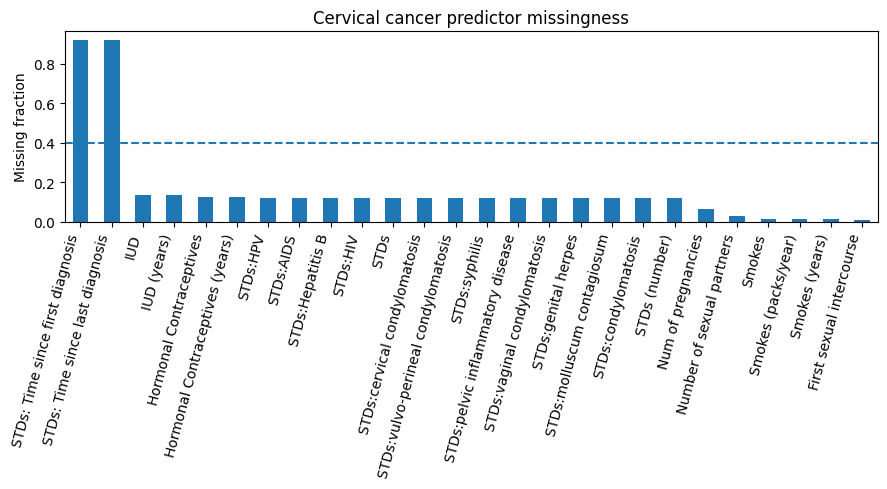

In [5]:
# Figure 2: cervical missingness before threshold removal
miss = cervical_raw.replace('?', np.nan).isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(9,5))
miss.plot(kind='bar')
plt.axhline(0.40, linestyle='--')
plt.ylabel('Missing fraction')
plt.title('Cervical cancer predictor missingness')
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(FIG,'fig2_cervical_missingness.png'), dpi=180, bbox_inches='tight')
plt.show()

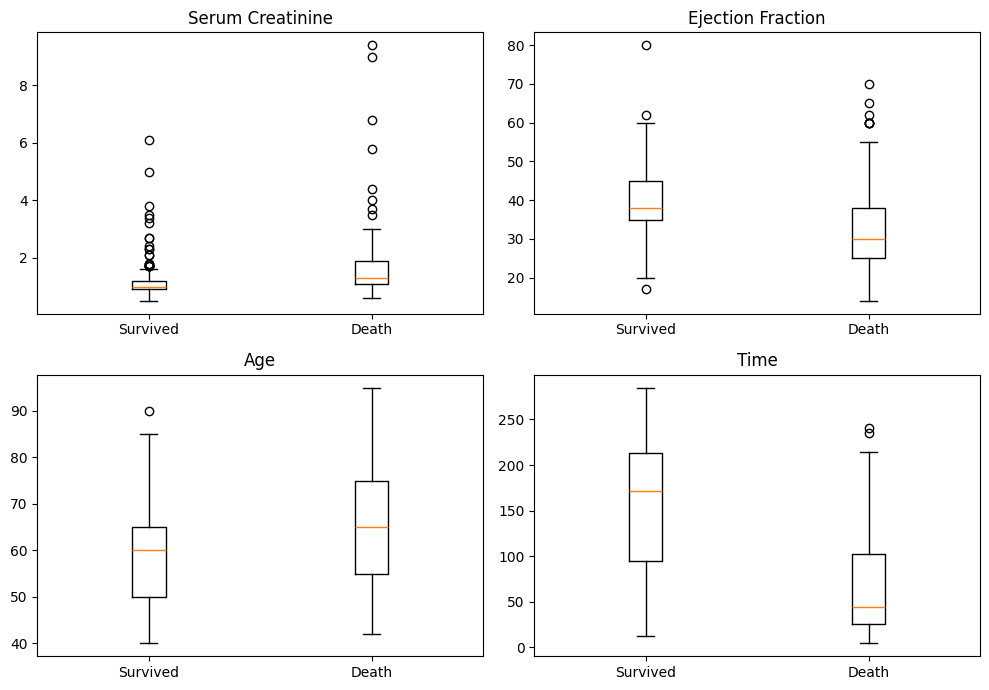

In [6]:
# Figure 3: heart-failure distributions by outcome for recurring important predictors
features = ['serum_creatinine','ejection_fraction','age','time']
fig, axes = plt.subplots(2,2,figsize=(10,7))
for ax, f in zip(axes.ravel(), features):
    groups = [heart.loc[heart.DEATH_EVENT==0,f], heart.loc[heart.DEATH_EVENT==1,f]]
    ax.boxplot(groups, labels=['Survived','Death'])
    ax.set_title(f.replace('_',' ').title())
plt.tight_layout()
plt.savefig(os.path.join(FIG,'fig3_heart_predictors_by_outcome.png'), dpi=180, bbox_inches='tight')
plt.show()

## 3. Supervised modeling

A 75/25 stratified train/test split is used throughout to match the prior milestone analysis. Weighted F1 is emphasized for the seven-class obesity task. For heart failure and cervical cancer, positive-class recall, F1, and ROC AUC are emphasized because the event classes are less common and false negatives are important.

In [7]:
# Preprocessing helpers
X_ob = obesity.drop(columns='NObeyesdad')
y_ob = obesity['NObeyesdad']
ob_num = X_ob.select_dtypes(exclude='object').columns.tolist()
ob_cat = X_ob.select_dtypes(include='object').columns.tolist()
ob_pre = ColumnTransformer([
    ('num', Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]), ob_num),
    ('cat', Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]), ob_cat)
])

X_hf = heart.drop(columns='DEATH_EVENT')
y_hf = heart['DEATH_EVENT']

Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(X_ob,y_ob,test_size=.25,random_state=RANDOM_STATE,stratify=y_ob)
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(X_hf,y_hf,test_size=.25,random_state=RANDOM_STATE,stratify=y_hf)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_cerv,y_cerv,test_size=.25,random_state=RANDOM_STATE,stratify=y_cerv)

In [8]:
# Obesity models
ob_models = {
    'Logistic regression': LogisticRegression(max_iter=3000),
    'Random forest': RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, min_samples_leaf=2),
    'KNN (Manhattan, k=3)': KNeighborsClassifier(n_neighbors=3, metric='manhattan', weights='distance'),
    'Gradient boosting': GradientBoostingClassifier(learning_rate=.1,max_depth=2,min_samples_leaf=3,n_estimators=125,random_state=RANDOM_STATE)
}
ob_rows=[]; fitted_ob={}
for name, model in ob_models.items():
    p=Pipeline([('pre',ob_pre),('model',model)])
    p.fit(Xo_tr,yo_tr); pred=p.predict(Xo_te)
    ob_rows.append([name, accuracy_score(yo_te,pred), f1_score(yo_te,pred,average='weighted')])
    fitted_ob[name]=p
ob_results=pd.DataFrame(ob_rows,columns=['Model','Accuracy','Weighted F1']).sort_values('Weighted F1',ascending=False)
ob_results

,Model,Accuracy,Weighted F1
3,Gradient boosting,0.952652,0.953136
1,Random forest,0.931818,0.933972
2,"KNN (Manhattan, k=3)",0.886364,0.883361
0,Logistic regression,0.878788,0.877726


In [9]:
# Heart models
heart_models = {
    'Logistic regression': Pipeline([('scale',StandardScaler()),('model',LogisticRegression(max_iter=2000,class_weight='balanced'))]),
    'Random forest': RandomForestClassifier(n_estimators=400,random_state=RANDOM_STATE,class_weight='balanced',min_samples_leaf=2),
    'Gradient boosting': GradientBoostingClassifier(learning_rate=.1,max_depth=1,min_samples_leaf=3,n_estimators=75,random_state=RANDOM_STATE)
}
h_rows=[]; fitted_h={}
for name, model in heart_models.items():
    model.fit(Xh_tr,yh_tr); pred=model.predict(Xh_te); prob=model.predict_proba(Xh_te)[:,1]
    h_rows.append([name,accuracy_score(yh_te,pred),precision_score(yh_te,pred),recall_score(yh_te,pred),f1_score(yh_te,pred),roc_auc_score(yh_te,prob)])
    fitted_h[name]=model
heart_results=pd.DataFrame(h_rows,columns=['Model','Accuracy','Precision','Recall','F1','AUC']).sort_values('AUC',ascending=False)
heart_results

,Model,Accuracy,Precision,Recall,F1,AUC
1,Random forest,0.826667,0.761905,0.666667,0.711111,0.890523
2,Gradient boosting,0.840000,0.928571,0.541667,0.684211,0.883578
0,Logistic regression,0.786667,0.666667,0.666667,0.666667,0.862745


In [10]:
# Cervical models
cerv_models = {
    'Logistic regression (balanced)': Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler()),('model',LogisticRegression(max_iter=3000,class_weight='balanced'))]),
    'Random forest (balanced)': Pipeline([('impute',SimpleImputer(strategy='median')),('model',RandomForestClassifier(n_estimators=500,random_state=RANDOM_STATE,class_weight='balanced',min_samples_leaf=2))]),
    'Gradient boosting': Pipeline([('impute',SimpleImputer(strategy='median')),('model',GradientBoostingClassifier(learning_rate=.1,max_depth=2,min_samples_leaf=3,n_estimators=125,random_state=RANDOM_STATE))])
}
c_rows=[]; fitted_c={}
for name, model in cerv_models.items():
    model.fit(Xc_tr,yc_tr); pred=model.predict(Xc_te); prob=model.predict_proba(Xc_te)[:,1]
    c_rows.append([name,accuracy_score(yc_te,pred),precision_score(yc_te,pred,zero_division=0),recall_score(yc_te,pred),f1_score(yc_te,pred),roc_auc_score(yc_te,prob)])
    fitted_c[name]=model
cerv_results=pd.DataFrame(c_rows,columns=['Model','Accuracy','Precision','Recall','F1','AUC']).sort_values('AUC',ascending=False)
cerv_results

,Model,Accuracy,Precision,Recall,F1,AUC
1,Random forest (balanced),0.934884,0.500000,0.071429,0.125000,0.702559
2,Gradient boosting,0.944186,1.000000,0.142857,0.250000,0.616205
0,Logistic regression (balanced),0.800000,0.128205,0.357143,0.188679,0.580313


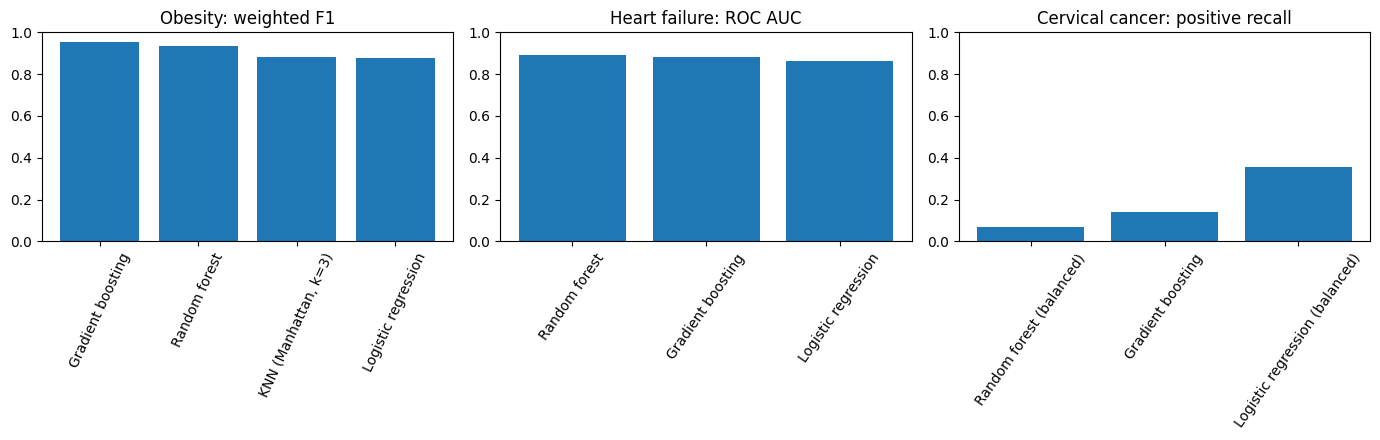

In [11]:
# Figure 4: supervised model comparison
fig, axes = plt.subplots(1,3,figsize=(14,4.5))
axes[0].bar(ob_results['Model'],ob_results['Weighted F1']); axes[0].set_ylim(0,1); axes[0].set_title('Obesity: weighted F1'); axes[0].tick_params(axis='x',rotation=65)
axes[1].bar(heart_results['Model'],heart_results['AUC']); axes[1].set_ylim(0,1); axes[1].set_title('Heart failure: ROC AUC'); axes[1].tick_params(axis='x',rotation=55)
axes[2].bar(cerv_results['Model'],cerv_results['Recall']); axes[2].set_ylim(0,1); axes[2].set_title('Cervical cancer: positive recall'); axes[2].tick_params(axis='x',rotation=55)
plt.tight_layout()
plt.savefig(os.path.join(FIG,'fig4_supervised_comparison.png'),dpi=180,bbox_inches='tight')
plt.show()

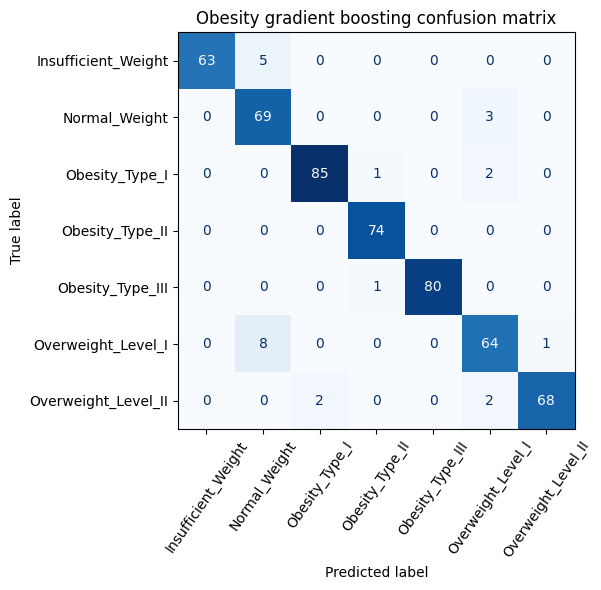

In [12]:
# Figure 5: obesity gradient boosting confusion matrix
best_ob=fitted_ob['Gradient boosting']
pred_ob=best_ob.predict(Xo_te)
fig, ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(yo_te,pred_ob,ax=ax,xticks_rotation=55,cmap='Blues',colorbar=False)
ax.set_title('Obesity gradient boosting confusion matrix')
plt.tight_layout()
plt.savefig(os.path.join(FIG,'fig5_obesity_gb_cm.png'),dpi=180,bbox_inches='tight')
plt.show()

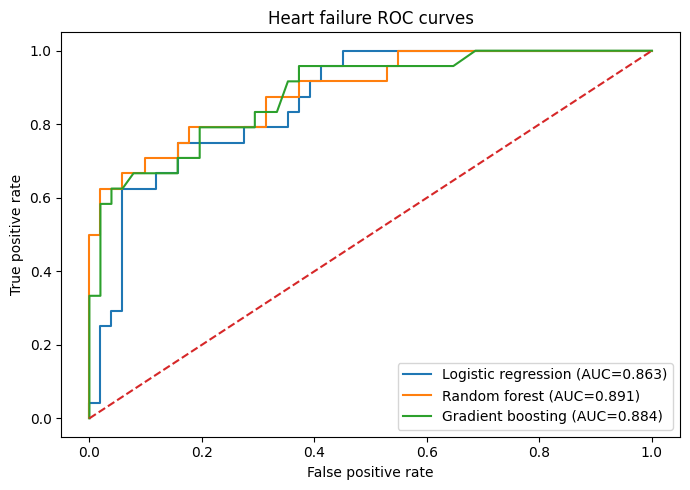

In [13]:
# Figure 6: heart ROC curves
plt.figure(figsize=(7,5))
for name,model in fitted_h.items():
    prob=model.predict_proba(Xh_te)[:,1]
    fpr,tpr,_=roc_curve(yh_te,prob)
    auc=roc_auc_score(yh_te,prob)
    plt.plot(fpr,tpr,label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'--')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Heart failure ROC curves'); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG,'fig6_heart_roc.png'),dpi=180,bbox_inches='tight'); plt.show()

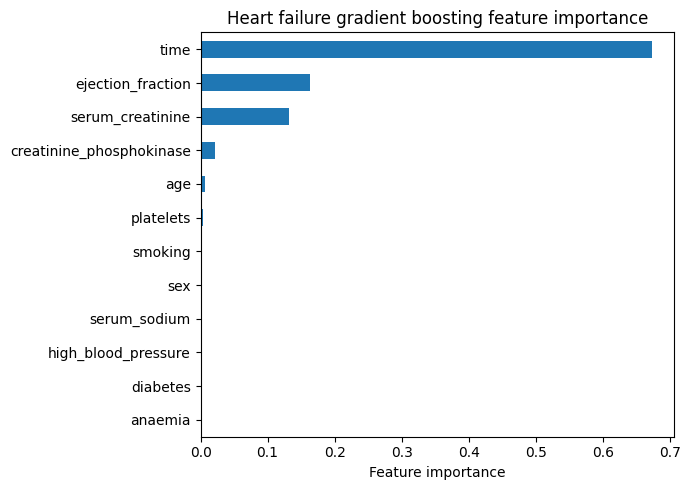

time                        0.673375
ejection_fraction           0.163363
serum_creatinine            0.131823
creatinine_phosphokinase    0.021111
age                         0.006410
platelets                   0.003918
diabetes                    0.000000
anaemia                     0.000000
dtype: float64

In [14]:
# Figure 7: gradient boosting heart feature importance
hf_gb=fitted_h['Gradient boosting']
imp=pd.Series(hf_gb.feature_importances_,index=X_hf.columns).sort_values(ascending=True)
plt.figure(figsize=(7,5)); imp.plot(kind='barh'); plt.xlabel('Feature importance'); plt.title('Heart failure gradient boosting feature importance')
plt.tight_layout(); plt.savefig(os.path.join(FIG,'fig7_heart_feature_importance.png'),dpi=180,bbox_inches='tight'); plt.show()
imp.sort_values(ascending=False).head(8)

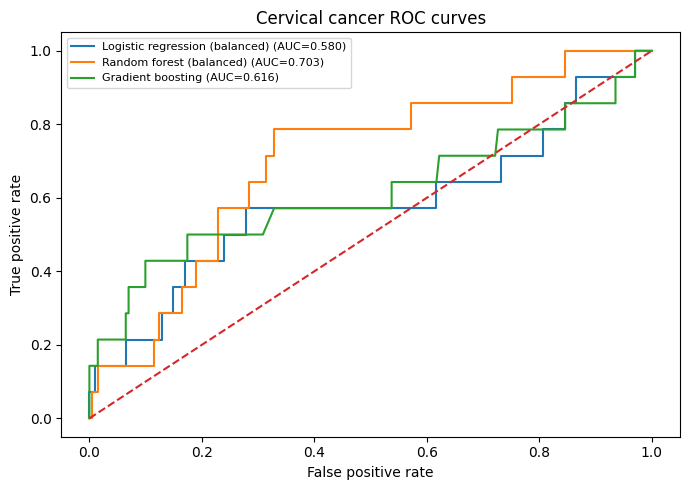

In [15]:
# Figure 8: cervical ROC curves
plt.figure(figsize=(7,5))
for name,model in fitted_c.items():
    prob=model.predict_proba(Xc_te)[:,1]
    fpr,tpr,_=roc_curve(yc_te,prob)
    auc=roc_auc_score(yc_te,prob)
    plt.plot(fpr,tpr,label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'--')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('Cervical cancer ROC curves'); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG,'fig8_cervical_roc.png'),dpi=180,bbox_inches='tight'); plt.show()

## 4. Obesity clustering

The obesity target is withheld during clustering. Numeric features are standardized and categorical features one-hot encoded. PCA is used only for visualization and for the DBSCAN representation. K-means and hierarchical clustering are compared using silhouette score and adjusted Rand index (ARI) against the withheld obesity label.

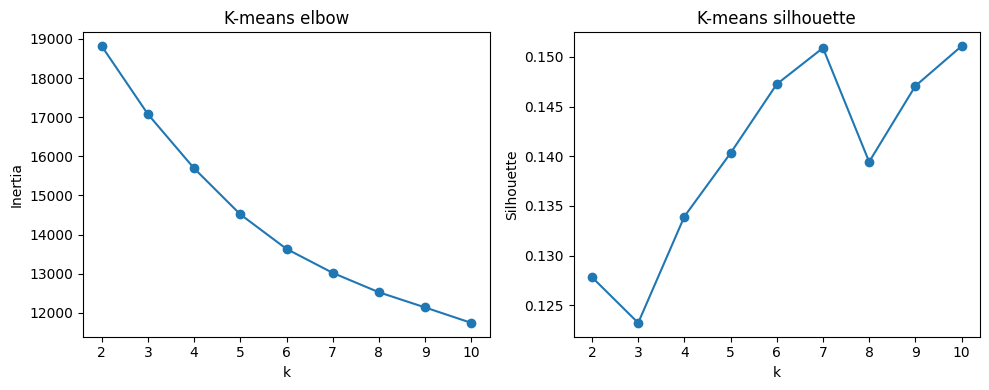

Best tested k: 10 silhouette: 0.1510871704791113


In [16]:
# Dense standardized feature representation
X_ob_enc = ob_pre.fit_transform(X_ob)
if hasattr(X_ob_enc,'toarray'): X_ob_enc=X_ob_enc.toarray()

# K-means k search
ks=range(2,11); inertias=[]; sils=[]
for k in ks:
    km=KMeans(n_clusters=k,random_state=RANDOM_STATE,n_init=20).fit(X_ob_enc)
    inertias.append(km.inertia_); sils.append(silhouette_score(X_ob_enc,km.labels_))
best_k=ks[int(np.argmax(sils))]

fig, axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot(list(ks),inertias,marker='o'); axes[0].set_title('K-means elbow'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[1].plot(list(ks),sils,marker='o'); axes[1].set_title('K-means silhouette'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
plt.tight_layout(); plt.savefig(os.path.join(FIG,'fig9_kmeans_selection.png'),dpi=180,bbox_inches='tight'); plt.show()
print('Best tested k:',best_k,'silhouette:',max(sils))

In [17]:
# PCA and clustering comparisons
pca2=PCA(n_components=2,random_state=RANDOM_STATE)
X_pca=pca2.fit_transform(X_ob_enc)
pca5=PCA(n_components=5,random_state=RANDOM_STATE)
X_pca5=pca5.fit_transform(X_ob_enc)
km=KMeans(n_clusters=10,random_state=RANDOM_STATE,n_init=20).fit(X_ob_enc)
km_sil=silhouette_score(X_ob_enc,km.labels_); km_ari=adjusted_rand_score(y_ob,km.labels_)

# Milestone Two used a five-component PCA representation for density/hierarchical clustering.
db=DBSCAN(eps=1.045,min_samples=10).fit(X_pca5)
mask=db.labels_!=-1
n_clusters=len(set(db.labels_))-(1 if -1 in db.labels_ else 0)
noise=(db.labels_==-1).mean()
db_sil=silhouette_score(X_pca5[mask],db.labels_[mask]) if n_clusters>1 and mask.sum()>1 else np.nan

hac=AgglomerativeClustering(n_clusters=10,linkage='ward').fit(X_pca5)
hac_sil=silhouette_score(X_pca5,hac.labels_); hac_ari=adjusted_rand_score(y_ob,hac.labels_)

cluster_results=pd.DataFrame([
    ['K-means',10,km_sil,km_ari,0.0],
    ['DBSCAN',n_clusters,db_sil,np.nan,noise],
    ['HAC (Ward)',10,hac_sil,hac_ari,0.0]
],columns=['Method','Clusters','Silhouette','ARI vs obesity label','Noise fraction'])
cluster_results

,Method,Clusters,Silhouette,ARI vs obesity label,Noise fraction
0,K-means,10,0.151087,0.175395,0.000000
1,DBSCAN,4,0.101248,NaN,0.111795
2,HAC (Ward),10,0.186744,0.220602,0.000000


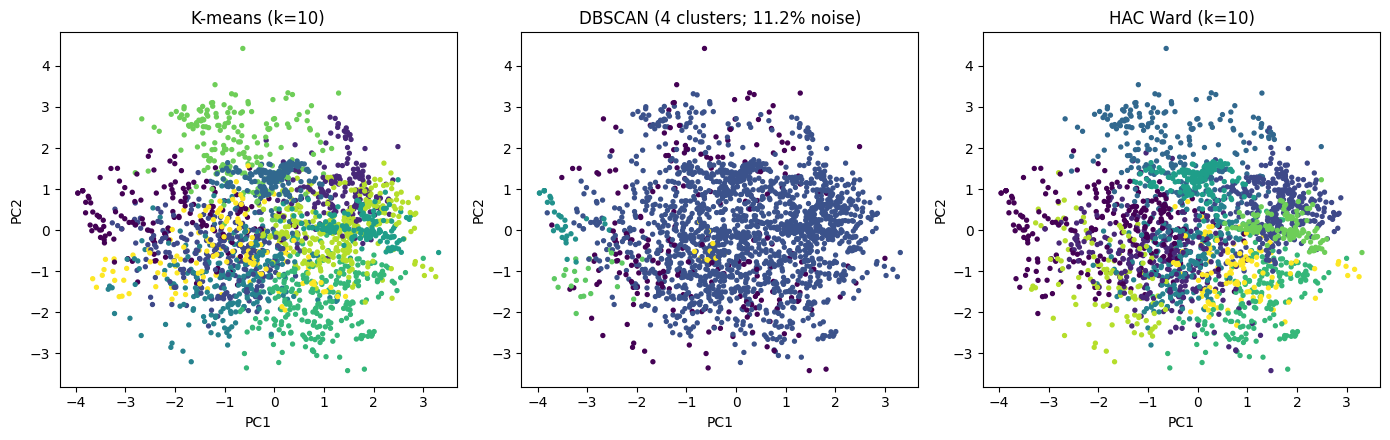

In [18]:
# Figure 10: cluster PCA views
fig,axes=plt.subplots(1,3,figsize=(14,4.5))
axes[0].scatter(X_pca[:,0],X_pca[:,1],c=km.labels_,s=8); axes[0].set_title(f'K-means (k=10)')
axes[1].scatter(X_pca[:,0],X_pca[:,1],c=db.labels_,s=8); axes[1].set_title(f'DBSCAN ({n_clusters} clusters; {noise:.1%} noise)')
axes[2].scatter(X_pca[:,0],X_pca[:,1],c=hac.labels_,s=8); axes[2].set_title('HAC Ward (k=10)')
for ax in axes: ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout(); plt.savefig(os.path.join(FIG,'fig10_cluster_pca.png'),dpi=180,bbox_inches='tight'); plt.show()

## 5. Key reproducible results

The Milestone Two tuned models are reproduced by the 75/25 split used here: obesity KNN is approximately 0.886 accuracy / 0.883 weighted F1; obesity gradient boosting is approximately 0.953 weighted F1; heart gradient boosting is approximately 0.840 accuracy, 0.542 recall, 0.684 F1, and 0.884 AUC; cervical gradient boosting is approximately 0.944 accuracy but only 0.143 recall and 0.250 F1.

In [19]:
# Save results for report generation
results = {
    'summary': summary.to_dict(orient='records'),
    'obesity_models': ob_results.to_dict(orient='records'),
    'heart_models': heart_results.to_dict(orient='records'),
    'cervical_models': cerv_results.to_dict(orient='records'),
    'clusters': cluster_results.to_dict(orient='records'),
    'removed_cervical_columns': removed_high_missing,
    'heart_feature_importance': imp.sort_values(ascending=False).to_dict(),
    'obesity_class_counts': obesity.NObeyesdad.value_counts().to_dict(),
    'heart_event_counts': heart.DEATH_EVENT.value_counts().to_dict(),
    'cervical_biopsy_counts': cervical.Biopsy.value_counts().to_dict(),
}
with open('/mnt/data/m3work/results.json','w') as f: json.dump(results,f,indent=2)
print(json.dumps(results, indent=2)[:5000])

{
  "summary": [
    {
      "Dataset": "Obesity",
      "Rows": 2111,
      "Raw columns": 17,
      "Target": "NObeyesdad",
      "Target type": "7-class",
      "Positive/event count": "n/a",
      "Missing-data note": "None in file"
    },
    {
      "Dataset": "Heart failure",
      "Rows": 299,
      "Raw columns": 13,
      "Target": "DEATH_EVENT",
      "Target type": "Binary",
      "Positive/event count": 96,
      "Missing-data note": "None in file"
    },
    {
      "Dataset": "Cervical cancer",
      "Rows": 858,
      "Raw columns": 36,
      "Target": "Biopsy",
      "Target type": "Binary",
      "Positive/event count": 55,
      "Missing-data note": "'?' converted to missing; >40% columns removed"
    }
  ],
  "obesity_models": [
    {
      "Model": "Gradient boosting",
      "Accuracy": 0.9526515151515151,
      "Weighted F1": 0.9531357956451987
    },
    {
      "Model": "Random forest",
      "Accuracy": 0.9318181818181818,
      "Weighted F1": 0.933971960449846

## 6. Interpretation notes

1. **Obesity classification is the strongest modeling use case.** Gradient boosting performs best and KNN remains competitive, while clustering yields much weaker separation than supervised classification.
2. **Heart failure has useful ranking signal but limited recall at the default threshold.** The repeated importance of follow-up time, serum creatinine, ejection fraction, and age supports a consistent predictive pattern, but the sample is too small for deployment claims.
3. **Cervical cancer illustrates the danger of accuracy under severe imbalance.** The tuned gradient-boosting model achieves high accuracy while missing most positive biopsy cases. Balanced baselines can increase recall, but the dataset still requires careful validation and richer positive-case data before screening use.
4. **Clusters should be treated as exploratory profiles.** Low silhouette/ARI values mean the obesity predictor space is overlapping rather than divided into crisp natural disease classes.